# Classify recordings with clinical features

In [1]:
from pathlib import Path
from time import perf_counter

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.svm import SVC
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from tabm import TabM
from tqdm import tqdm

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

## Load the data

In [ ]:
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / 'requirements.txt').is_file() and (path / 'notebooks').is_dir())
SPLIT_DIR = PROJECT_ROOT / 'outputs' / '03_split_and_distribution' / 'splits'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / '04_model_comparison'
MODEL_FILE = OUTPUT_DIR / 'models' / 'clinical_models.pkl'
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SEEDS = (11, 29, 42, 73, 101)
CLASSES = np.array(['healthy', 'other', 'rbd'])

ARCHITECTURE_FEATURES = ['sleep_efficiency', 'waso_min', 'awakenings_per_h', 'stage_shifts_per_h', 'pct_rem', 'sws_first_half']
CAP_FEATURES = ['cap_rate', 'cap_a_index', 'cap_a3_index', 'cap_a1_share']
RSWA_FEATURES = ['rem_atonia_index', 'rem_any3_bg2', 'diff_phasic1_local3', 'rem_tonic_bg2', 'diff_log_rms_p90']
WINDOW_FEATURES = ['sws_delta', 's2_emg_sd', 'rem_theta_alpha']
FEATURES = RSWA_FEATURES + WINDOW_FEATURES + ARCHITECTURE_FEATURES + CAP_FEATURES


splits = {name: pd.read_csv(SPLIT_DIR / f'{name}.csv') for name in ('train', 'validation')}
split_ids = pd.concat([table['record_id'] for table in splits.values()], ignore_index=True)
if not split_ids.is_unique:
    raise ValueError('Training and validation contain duplicate recordings.')

## Define the models

In [3]:
class FixedEpochTabM(ClassifierMixin, BaseEstimator):
    """TabM trained for a fixed number of full-batch epochs on already balanced data."""

    def __init__(self, epochs=40, seed=42, verbose=False):
        self.epochs = epochs
        self.seed = seed
        self.verbose = verbose

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.scaler_ = StandardScaler().fit(X)
        x = torch.tensor(self.scaler_.transform(X), dtype=torch.float32)
        self.model_ = TabM.make(n_num_features=x.shape[1], d_out=len(self.classes_),
                                n_blocks=2, d_block=64, dropout=0.1, k=16)
        target = torch.tensor(encoded, dtype=torch.long).repeat_interleave(self.model_.k)
        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=0.001, weight_decay=0.0001)
        self.model_.train()
        self.loss_curve_ = []
        for epoch in range(self.epochs):
            optimizer.zero_grad()
            loss = F.cross_entropy(self.model_(x).reshape(-1, len(self.classes_)), target)
            loss.backward()
            optimizer.step()
            self.loss_curve_.append(float(loss.detach()))
            if self.verbose and (epoch == 0 or (epoch + 1) % 10 == 0):
                print(f'Epoch {epoch + 1:02d}/{self.epochs} | training loss: {loss.item():.4f}')
        self.model_.eval()
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            x = torch.tensor(self.scaler_.transform(X), dtype=torch.float32)
            return self.model_(x).softmax(dim=-1).mean(dim=1).numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def oversample(y, rng):
    groups = [np.flatnonzero(y == label) for label in np.unique(y)]
    largest = max(len(group) for group in groups)
    selected = [rng.choice(group, size=largest, replace=len(group) < largest) for group in groups]
    return rng.permutation(np.concatenate(selected))

def extra_trees(seed):
    return ExtraTreesClassifier(n_estimators=1000, min_samples_leaf=2, max_features=0.5,
                                class_weight='balanced', random_state=seed, n_jobs=-1)

def make_models(seed, verbose=False):
    logistic = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
    ensemble = VotingClassifier([('logistic_regression', logistic), ('extra_trees', extra_trees(seed))], voting='soft')
    estimators = {
        'Majority baseline': DummyClassifier(strategy='most_frequent'),
        'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
        'RBF SVM': make_pipeline(RobustScaler(), SVC(C=1, kernel='rbf', class_weight='balanced')),
        'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=seed, n_jobs=1),
        'XGBoost': XGBClassifier(n_estimators=40, max_depth=3, learning_rate=0.05, reg_lambda=3,
                                 objective='multi:softprob', num_class=len(CLASSES), random_state=seed, n_jobs=1),
        'CatBoost': CatBoostClassifier(iterations=60, depth=3, learning_rate=0.05, loss_function='MultiClass',
                                       random_seed=seed, thread_count=1, verbose=False, allow_writing_files=False),
        'TabM': FixedEpochTabM(seed=seed, verbose=verbose),
        'Extra trees': extra_trees(seed),
        'Soft-voting ensemble': ensemble,
    }
    return {name: make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), model)
            for name, model in estimators.items()}

OVERSAMPLED_MODELS = {'Logistic regression', 'Random forest', 'XGBoost', 'CatBoost', 'TabM'}

def scores(y, prediction):
    recalls = recall_score(y, prediction, labels=np.arange(len(CLASSES)), average=None, zero_division=0)
    return {'balanced_accuracy': balanced_accuracy_score(y, prediction),
            'macro_f1': f1_score(y, prediction, labels=np.arange(len(CLASSES)), average='macro', zero_division=0),
            **{f'{name}_recall': value for name, value in zip(CLASSES, recalls)}}

## Cross-validation

Compare the models on the training split using five seeds and three folds.

In [4]:
def cross_validate(table):
    X, y = table[FEATURES], pd.Categorical(table['class_name'], categories=CLASSES).codes
    predictions = []
    for seed in SEEDS:
        splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
        for fold, (fit, held) in enumerate(splitter.split(X, y)):
            model_seed = seed + fold
            balanced = fit[oversample(y[fit], np.random.default_rng(model_seed))]
            for name, model in make_models(model_seed).items():
                indices = balanced if name in OVERSAMPLED_MODELS else fit
                model.fit(X.iloc[indices], y[indices])
                prediction = np.asarray(model.predict(X.iloc[held])).astype(int).ravel()
                predictions.extend({'seed': seed, 'model': name, 'record_id': table.iloc[index]['record_id'],
                                    'true': y[index], 'predicted': int(value)} for index, value in zip(held, prediction))
    out_of_fold = pd.DataFrame(predictions)
    if not out_of_fold.groupby(['seed', 'model', 'record_id']).size().eq(1).all():
        raise ValueError('Each recording must have one prediction per model and seed.')
    return pd.DataFrame([{'seed': seed, 'model': model, **scores(group['true'], group['predicted'])}
                         for (seed, model), group in out_of_fold.groupby(['seed', 'model'])])

def mean_and_spread(per_seed, metrics):
    grouped = per_seed.groupby('model')[metrics]
    mean = grouped.mean().sort_values(metrics[0], ascending=False)
    spread = grouped.std().loc[mean.index]
    return pd.DataFrame({metric: [f'{a:.3f} \u00b1 {b:.3f}' for a, b in zip(mean[metric], spread[metric])]
                         for metric in metrics}, index=mean.index)

metrics = ['balanced_accuracy', 'macro_f1', 'healthy_recall', 'other_recall', 'rbd_recall']
per_seed = cross_validate(splits['train'])
display(mean_and_spread(per_seed, metrics))

,balanced_accuracy,macro_f1,healthy_recall,other_recall,rbd_recall
model,,,,,
TabM,0.751 ± 0.026,0.650 ± 0.032,0.800 ± 0.050,0.576 ± 0.051,0.877 ± 0.069
RBF SVM,0.672 ± 0.043,0.603 ± 0.029,0.733 ± 0.061,0.590 ± 0.032,0.692 ± 0.122
Logistic regression,0.669 ± 0.042,0.641 ± 0.042,0.644 ± 0.093,0.717 ± 0.044,0.646 ± 0.069
Soft-voting ensemble,0.630 ± 0.045,0.609 ± 0.053,0.444 ± 0.136,0.722 ± 0.061,0.723 ± 0.088
CatBoost,0.593 ± 0.078,0.572 ± 0.071,0.400 ± 0.217,0.702 ± 0.047,0.677 ± 0.064
Extra trees,0.557 ± 0.050,0.565 ± 0.062,0.200 ± 0.093,0.839 ± 0.056,0.631 ± 0.064
Random forest,0.553 ± 0.072,0.553 ± 0.072,0.244 ± 0.183,0.800 ± 0.027,0.615 ± 0.094
XGBoost,0.482 ± 0.038,0.481 ± 0.041,0.244 ± 0.183,0.771 ± 0.059,0.431 ± 0.103
Majority baseline,0.333 ± 0.000,0.263 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000


## Cross-validation by staging

Repeat the cross-validation with the clinical features of each staging.

In [5]:
STAGING_DIR = PROJECT_ROOT / 'outputs' / '02_preprocessing' / 'staging' / 'clinical_features'
staging_features = {path.stem: pd.read_csv(path) for path in sorted(STAGING_DIR.glob('*.csv'))}
if not staging_features:
    raise FileNotFoundError('Run notebook 02 to create the clinical features of each staging.')

def with_staging(table, staging):
    return table[['record_id', 'class_name']].merge(staging_features[staging], on='record_id', how='left', validate='one_to_one')

staging_scores = {staging: cross_validate(with_staging(splits['train'], staging))
                  for staging in tqdm(staging_features, desc='Stagings', unit='staging')}
order = mean_and_spread(per_seed, ['balanced_accuracy']).index
for metric in ['balanced_accuracy', 'rbd_recall']:
    print('\n' + '-' * 40)
    print(metric)
    display(pd.DataFrame({staging: mean_and_spread(results, [metric])[metric]
                          for staging, results in staging_scores.items()}).loc[order])

Stagings: 100%|██████████| 4/4 [01:38<00:00, 24.58s/staging]


----------------------------------------
balanced_accuracy


,ensemble,gssc,manual,yasa
model,,,,
TabM,0.751 ± 0.026,0.753 ± 0.035,0.722 ± 0.057,0.726 ± 0.025
RBF SVM,0.672 ± 0.043,0.698 ± 0.049,0.687 ± 0.068,0.687 ± 0.018
Logistic regression,0.669 ± 0.042,0.654 ± 0.032,0.614 ± 0.044,0.645 ± 0.072
Soft-voting ensemble,0.630 ± 0.045,0.629 ± 0.031,0.643 ± 0.044,0.655 ± 0.028
CatBoost,0.593 ± 0.078,0.597 ± 0.058,0.653 ± 0.081,0.631 ± 0.095
Extra trees,0.557 ± 0.050,0.572 ± 0.053,0.557 ± 0.074,0.578 ± 0.078
Random forest,0.553 ± 0.072,0.581 ± 0.067,0.566 ± 0.073,0.564 ± 0.077
XGBoost,0.482 ± 0.038,0.519 ± 0.071,0.549 ± 0.065,0.546 ± 0.072
Majority baseline,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000



----------------------------------------
rbd_recall


,ensemble,gssc,manual,yasa
model,,,,
TabM,0.877 ± 0.069,0.877 ± 0.042,0.769 ± 0.109,0.815 ± 0.069
RBF SVM,0.692 ± 0.122,0.754 ± 0.100,0.692 ± 0.077,0.723 ± 0.069
Logistic regression,0.646 ± 0.069,0.585 ± 0.069,0.569 ± 0.088,0.600 ± 0.148
Soft-voting ensemble,0.723 ± 0.088,0.754 ± 0.114,0.662 ± 0.088,0.692 ± 0.054
CatBoost,0.677 ± 0.064,0.708 ± 0.064,0.646 ± 0.117,0.646 ± 0.103
Extra trees,0.631 ± 0.064,0.662 ± 0.069,0.585 ± 0.129,0.662 ± 0.088
Random forest,0.615 ± 0.094,0.677 ± 0.064,0.554 ± 0.126,0.646 ± 0.103
XGBoost,0.431 ± 0.103,0.615 ± 0.000,0.446 ± 0.034,0.585 ± 0.088
Majority baseline,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


## Training

Fit the models on the training and validation recordings and save them for later use.

In [6]:
steps = {'Majority baseline': 'Baseline', 'Logistic regression': 'Single fit', 'RBF SVM': 'Single fit',
         'Random forest': '300 trees', 'XGBoost': '40 boosting rounds', 'CatBoost': '60 boosting rounds',
         'TabM': '40 epochs', 'Extra trees': '1000 trees', 'Soft-voting ensemble': 'Two models'}

def fit_models(table):
    X, y = table[FEATURES], pd.Categorical(table['class_name'], categories=CLASSES).codes
    balanced = oversample(y, np.random.default_rng(42))
    models, rows = make_models(42), []
    for name, model in models.items():
        indices = balanced if name in OVERSAMPLED_MODELS else np.arange(len(table))
        started = perf_counter()
        model.fit(X.iloc[indices], y[indices])
        rows.append({'model': name, 'Fit rows': len(indices), 'Training': steps[name], 'Time (s)': perf_counter() - started})
    return models, pd.DataFrame(rows).set_index('model').round({'Time (s)': 2})

train_validation = pd.concat([splits['train'], splits['validation']], ignore_index=True)
models, training_summary = fit_models(train_validation)
MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
with MODEL_FILE.open('wb') as file:
    cloudpickle.dump({'models': models, 'features': FEATURES, 'classes': CLASSES.tolist(),
                      'training_ids': train_validation['record_id'].tolist()}, file)
print('\n' + '-' * 40)
print(f'Training data: {len(train_validation)} unique recordings, {training_summary["Fit rows"].max()} rows after oversampling')
display(training_summary)
losses = models['TabM'].named_steps['fixedepochtabm'].loss_curve_
epochs = [1, 10, 20, 30, 40]
print('\n' + '-' * 40)
print('TabM training loss (not validation loss):')
display(pd.DataFrame({'epoch': epochs, 'training_loss': [losses[epoch - 1] for epoch in epochs]}).set_index('epoch').round(4))
print('\n' + '-' * 40)
print(f'Saved models to {MODEL_FILE.relative_to(PROJECT_ROOT)}')


----------------------------------------
Training data: 74 unique recordings, 144 rows after oversampling


,Fit rows,Training,Time (s)
model,,,
Majority baseline,74,Baseline,0.00
Logistic regression,144,Single fit,0.01
RBF SVM,74,Single fit,0.00
Random forest,144,300 trees,0.16
XGBoost,144,40 boosting rounds,0.04
CatBoost,144,60 boosting rounds,0.05
TabM,144,40 epochs,0.15
Extra trees,74,1000 trees,0.62
Soft-voting ensemble,74,Two models,0.62



----------------------------------------
TabM training loss (not validation loss):


,training_loss
epoch,
1,1.1037
10,1.0465
20,0.9743
30,0.8746
40,0.7584



----------------------------------------
Saved models to outputs\04_model_comparison\models\clinical_models.pkl


## Test

Evaluate the trained models on the test split.

In [7]:
def evaluate(models, table):
    y = pd.Categorical(table['class_name'], categories=CLASSES).codes
    results, predictions = [], {}
    for name, model in models.items():
        prediction = np.asarray(model.predict(table[FEATURES])).astype(int).ravel()
        predictions[name] = prediction
        results.append({'model': name, **scores(y, prediction), 'accuracy': accuracy_score(y, prediction)})
    return pd.DataFrame(results).set_index('model'), predictions, y

test = pd.read_csv(SPLIT_DIR / 'test.csv')
if set(test['record_id']) & set(train_validation['record_id']):
    raise ValueError('The test split overlaps with the training or validation split.')
test_results, test_predictions, y_test = evaluate(models, test)
display(test_results.round(3))

,balanced_accuracy,macro_f1,healthy_recall,other_recall,rbd_recall,accuracy
model,,,,,,
Majority baseline,0.333,0.264,0.00,1.000,0.000,0.656
Logistic regression,0.837,0.774,0.75,0.762,1.000,0.812
RBF SVM,0.806,0.724,0.75,0.667,1.000,0.750
Random forest,0.837,0.774,0.75,0.762,1.000,0.812
XGBoost,0.710,0.663,0.75,0.667,0.714,0.688
CatBoost,0.837,0.774,0.75,0.762,1.000,0.812
TabM,0.726,0.584,0.75,0.429,1.000,0.594
Extra trees,0.821,0.800,0.75,0.857,0.857,0.844
Soft-voting ensemble,0.821,0.748,0.75,0.714,1.000,0.781


## Test confusion matrices

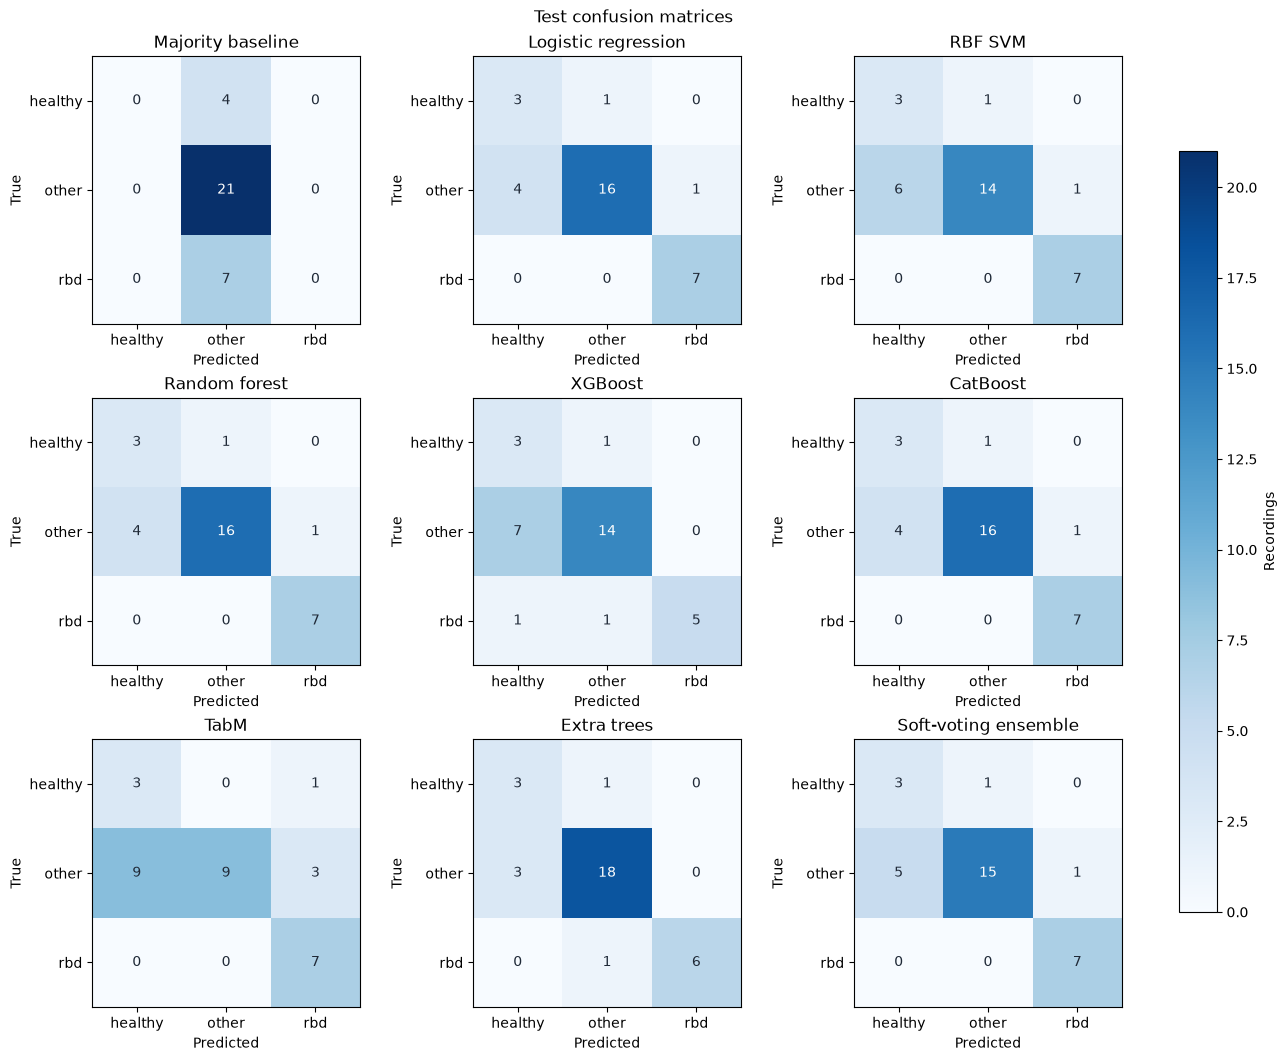

In [8]:
def plot_confusion_matrices(predictions, y, title, filename):
    columns = 3
    rows = (len(predictions) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(13, rows * 3.5), squeeze=False, layout='constrained')
    limit = np.bincount(y, minlength=len(CLASSES)).max()
    for ax, (name, prediction) in zip(axes.flat, predictions.items()):
        matrix = confusion_matrix(y, prediction, labels=np.arange(len(CLASSES)))
        image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=limit)
        for row in range(len(CLASSES)):
            for column in range(len(CLASSES)):
                value = matrix[row, column]
                ax.text(column, row, value, ha='center', va='center',
                        color='white' if value > limit / 2 else '#1f2937')
        ax.set(title=name, xticks=range(len(CLASSES)), yticks=range(len(CLASSES)),
               xticklabels=CLASSES, yticklabels=CLASSES, xlabel='Predicted', ylabel='True')

    for ax in list(axes.flat)[len(predictions):]:
        fig.delaxes(ax)
    fig.colorbar(image, ax=fig.axes, label='Recordings', shrink=0.8)
    fig.suptitle(title)
    fig.savefig(FIGURE_DIR / filename, bbox_inches='tight', pad_inches=0.18)
    plt.show()

plot_confusion_matrices(test_predictions, y_test, 'Test confusion matrices', 'test_confusion_matrices.png')

## Test by staging

Train and test the models with the clinical features of each staging.

In [9]:
staging_tests, staging_predictions = {}, {}
for staging in tqdm(staging_features, desc='Stagings', unit='staging'):
    fitted, _ = fit_models(with_staging(train_validation, staging))
    staging_tests[staging], staging_predictions[staging], _ = evaluate(fitted, with_staging(test, staging))
for metric in ['balanced_accuracy', 'rbd_recall']:
    print('\n' + '-' * 40)
    print(metric)
    display(pd.DataFrame({staging: results[metric] for staging, results in staging_tests.items()}).loc[order].round(3))

Stagings: 100%|██████████| 4/4 [00:07<00:00,  1.87s/staging]


----------------------------------------
balanced_accuracy


,ensemble,gssc,manual,yasa
model,,,,
TabM,0.726,0.742,0.758,0.694
RBF SVM,0.806,0.806,0.806,0.758
Logistic regression,0.837,0.774,0.758,0.774
Soft-voting ensemble,0.821,0.806,0.853,0.821
CatBoost,0.837,0.790,0.774,0.837
Extra trees,0.821,0.790,0.821,0.821
Random forest,0.837,0.806,0.837,0.821
XGBoost,0.710,0.675,0.742,0.806
Majority baseline,0.333,0.333,0.333,0.333



----------------------------------------
rbd_recall


,ensemble,gssc,manual,yasa
model,,,,
TabM,1.000,1.000,1.000,1.000
RBF SVM,1.000,1.000,1.000,1.000
Logistic regression,1.000,0.857,0.857,1.000
Soft-voting ensemble,1.000,0.857,1.000,1.000
CatBoost,1.000,0.857,0.857,1.000
Extra trees,0.857,0.714,0.857,0.857
Random forest,1.000,0.857,0.857,0.857
XGBoost,0.714,0.714,0.714,0.857
Majority baseline,0.000,0.000,0.000,0.000


## Test confusion matrices by staging

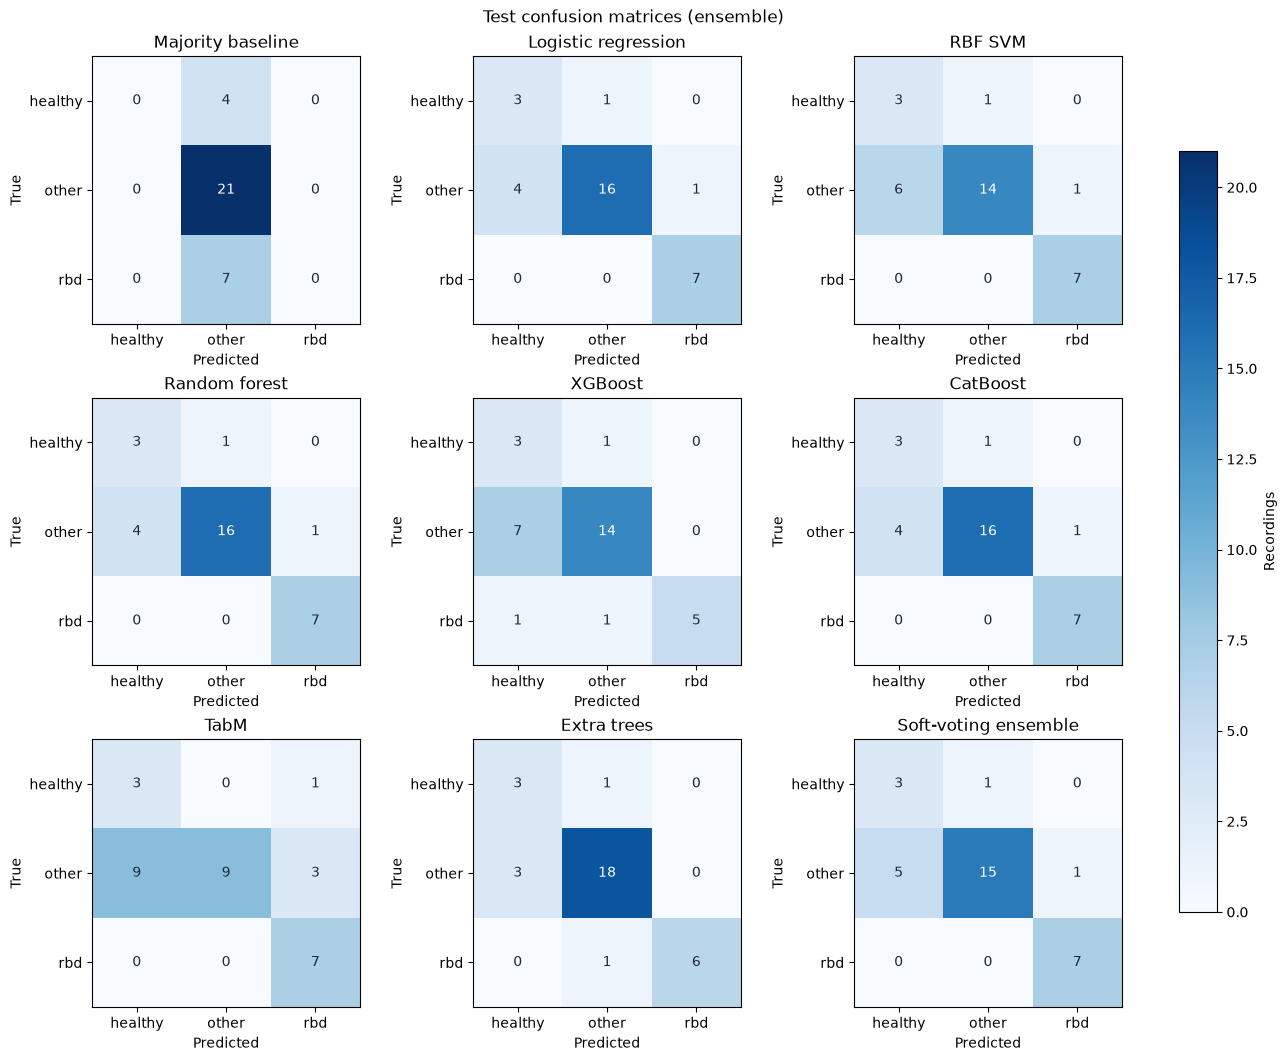

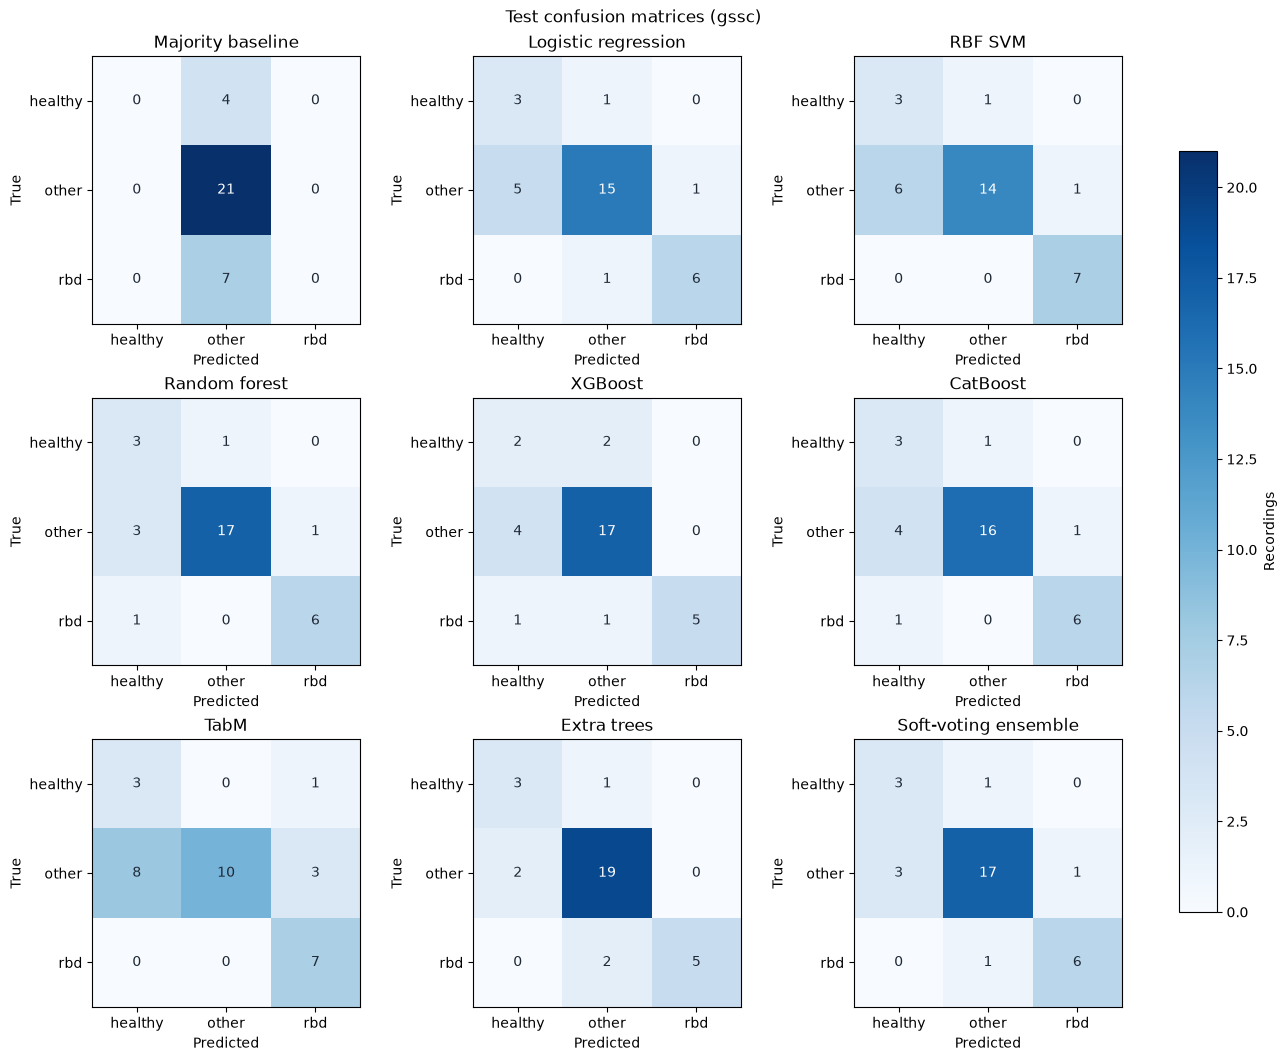

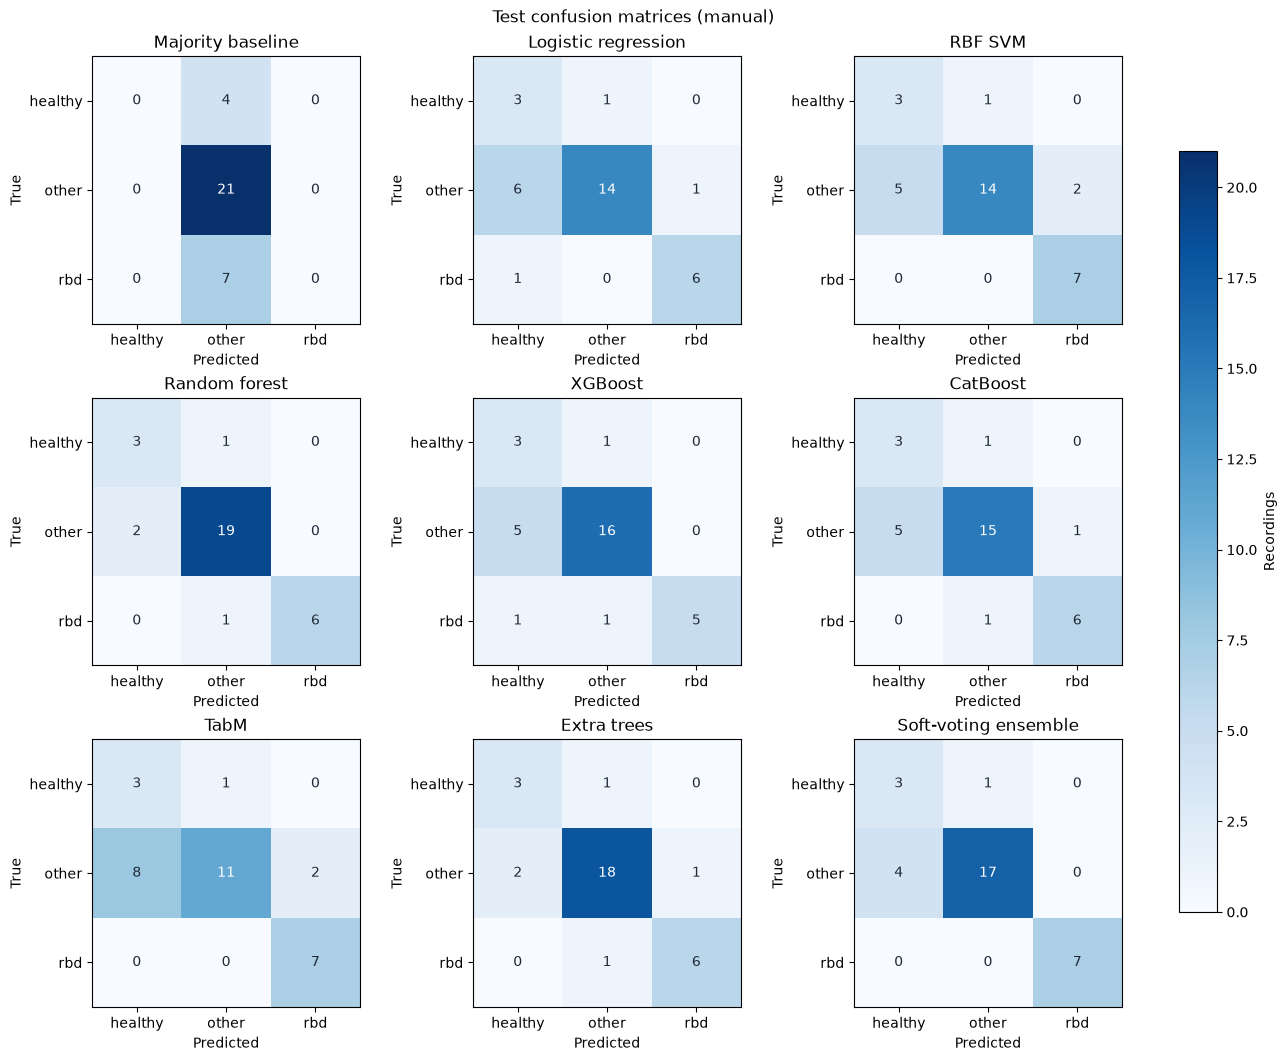

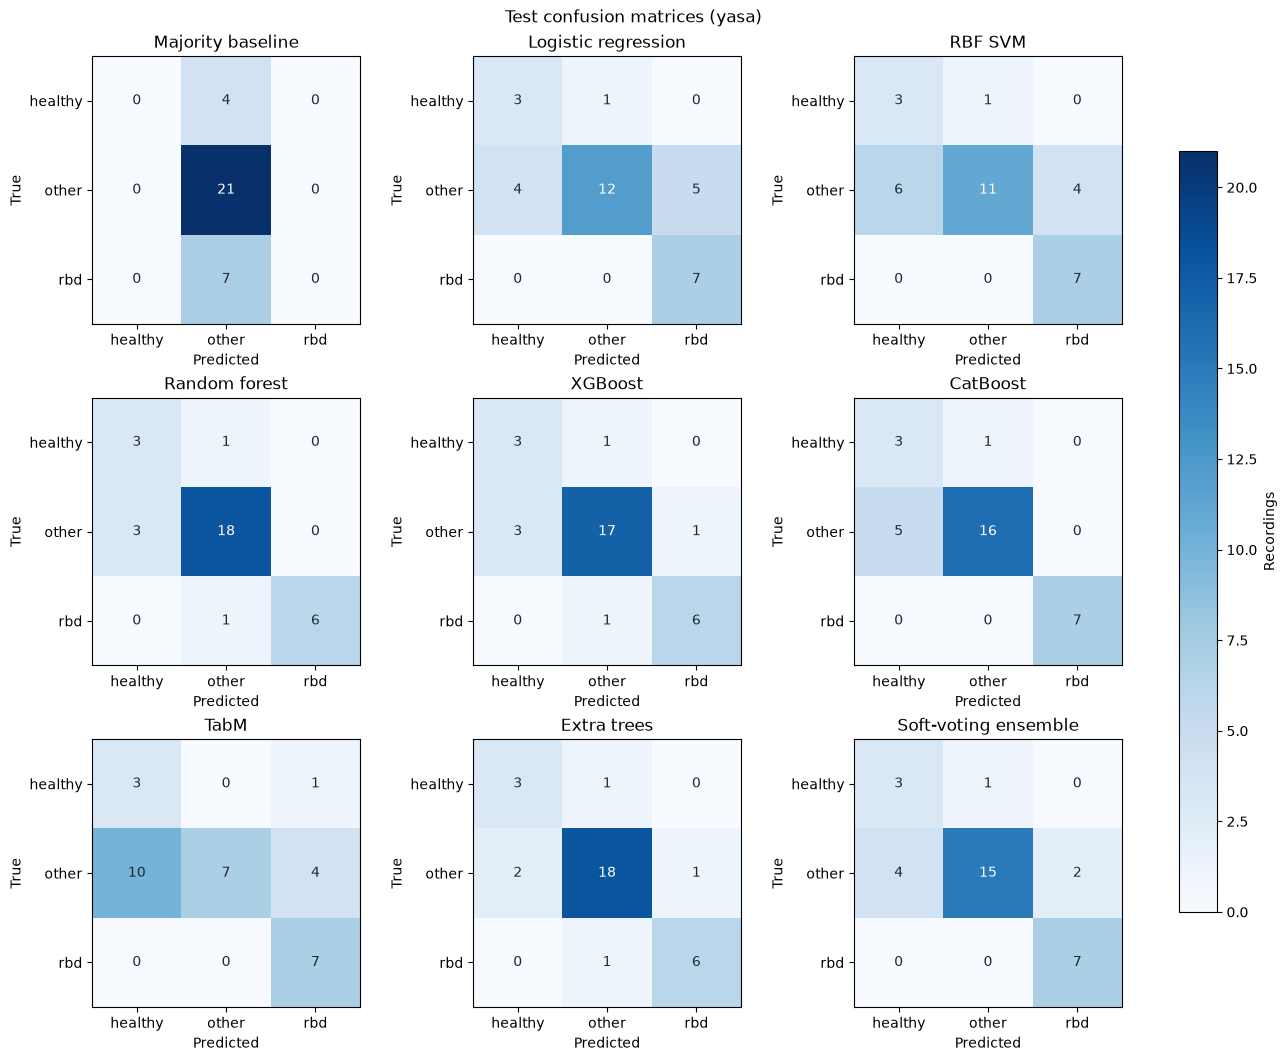

In [10]:
for staging, predictions in staging_predictions.items():
    plot_confusion_matrices(predictions, y_test, f'Test confusion matrices ({staging})', f'test_confusion_matrices_{staging}.png')